# Monte Carlo convergence for European options

This experiment compares Monte Carlo prices with Black–Scholes analytical values as the path count increases. It separates two ideas that are easy to confuse:

1. A **single estimate** can still move up or down as more paths are added. That is normal sampling noise.
2. The **typical error across repeated runs** should shrink approximately like $N^{-1/2}$.

To make the first plot easier to read, calls and puts have separate panels and use nested samples: each larger path count includes all paths from the smaller count. The second plot measures root mean squared error (RMSE) across independent replications. That is the appropriate comparison for the theoretical convergence rate.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from european_option_pricing.black_scholes import black_scholes
from european_option_pricing.monte_carlo import simulate_terminal_prices

COLORS = {'call': '#2463A5', 'put': '#C4515C'}
METHOD_COLORS = {'ordinary': '#2463A5', 'antithetic': '#C4515C'}
INK = '#263445'
MUTED = '#64748B'
GRID = '#DCE3EA'
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 10, 'figure.titlesize': 15, 'figure.titleweight': 'bold',
    'axes.edgecolor': '#C8D1DC', 'axes.labelcolor': INK, 'text.color': INK,
    'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'grid.alpha': 0.8,
    'legend.frameon': False, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'lines.linewidth': 2,
})

## Parameters and analytical benchmark

We use the standard at-the-money benchmark. The selected path counts are nested within a maximum sample of 200,000 paths.

In [2]:
parameters = {
    'S': 100.0,
    'K': 100.0,
    'T': 1.0,
    'r': 0.05,
    'sigma': 0.20,
    'q': 0.0,
}
path_counts = np.array([500, 1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000])
option_types = ['call', 'put']
analytical = {
    kind: black_scholes(**parameters, option_type=kind)
    for kind in option_types
}
print(f"Analytical call: {analytical['call']:.6f}")
print(f"Analytical put:  {analytical['put']:.6f}")

Analytical call: 10.450584
Analytical put:  5.573526


## One nested simulation

The following path shows one reproducible run. The shaded band is the estimate plus or minus 1.96 estimated standard errors. Because the samples are nested, adjacent estimates are strongly related, but they can still wiggle: each step adds a new batch of random payoffs.

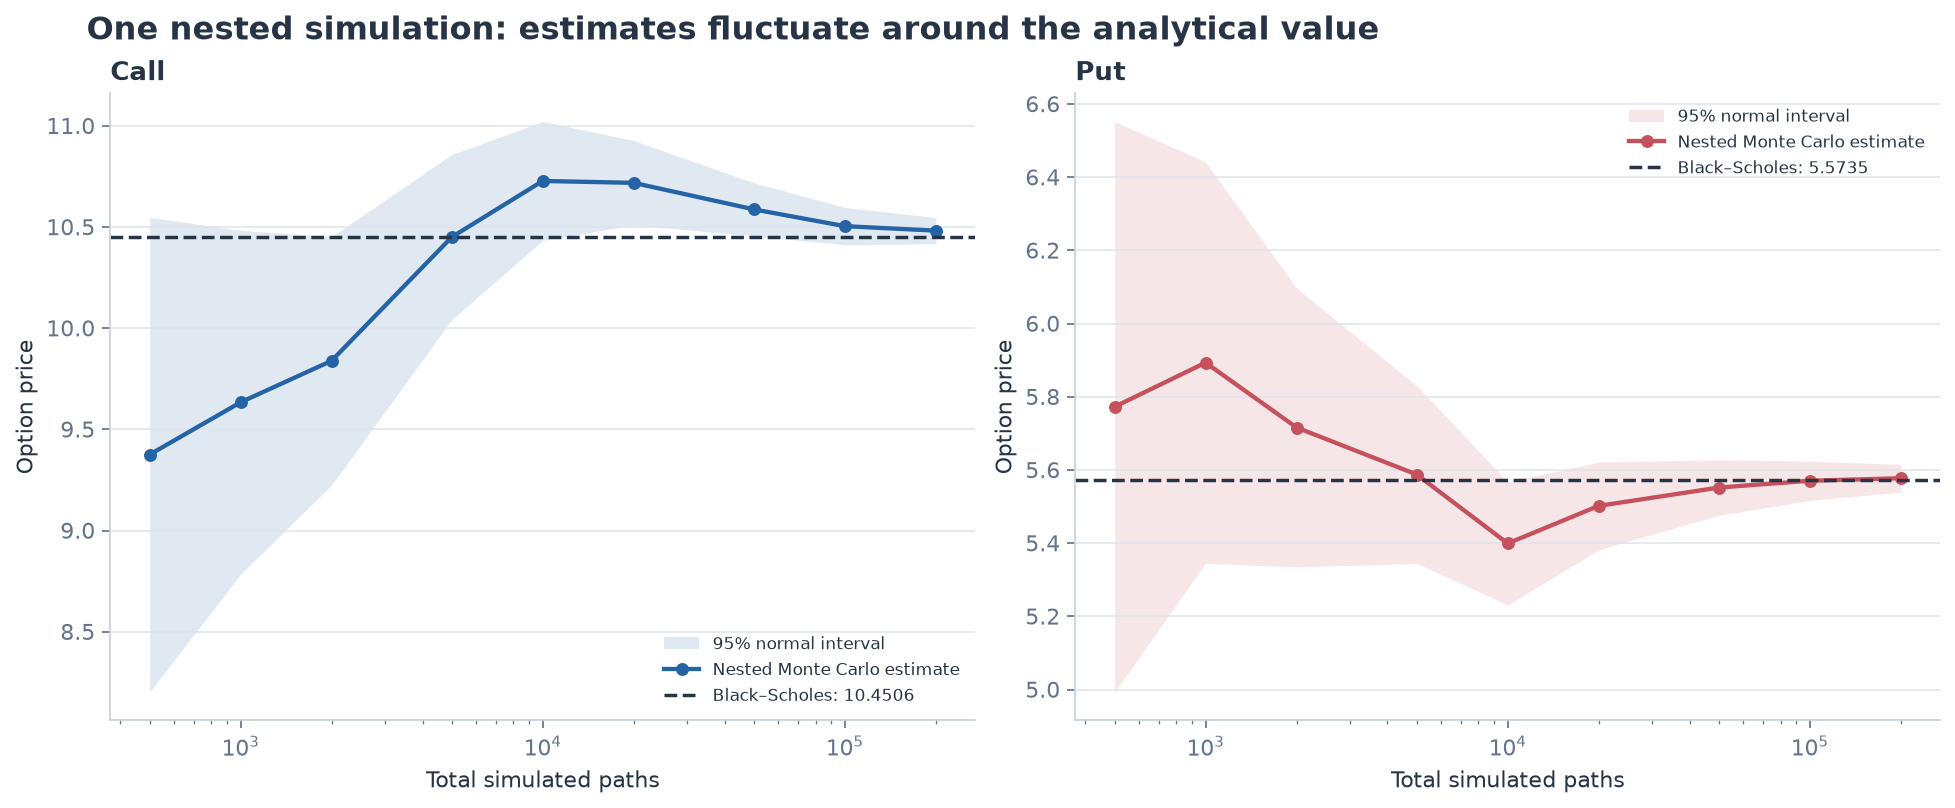

In [3]:
max_paths = int(path_counts[-1])
single_paths = simulate_terminal_prices(
    parameters['S'], parameters['T'], parameters['r'], parameters['sigma'],
    max_paths, q=parameters['q'], rng=8675309,
)
discount = np.exp(-parameters['r'] * parameters['T'])
single_results = {}

for kind in option_types:
    payoff = (
        np.maximum(single_paths - parameters['K'], 0.0)
        if kind == 'call'
        else np.maximum(parameters['K'] - single_paths, 0.0)
    )
    discounted = discount * payoff
    cumulative_sum = np.cumsum(discounted)
    cumulative_sum_sq = np.cumsum(discounted ** 2)
    n = path_counts.astype(float)
    means = cumulative_sum[path_counts - 1] / n
    variances = (cumulative_sum_sq[path_counts - 1] - n * means ** 2) / (n - 1)
    standard_errors = np.sqrt(np.maximum(variances, 0.0) / n)
    single_results[kind] = {'estimate': means, 'se': standard_errors}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1), constrained_layout=True)
for ax, kind in zip(axes, option_types):
    estimate = single_results[kind]['estimate']
    se = single_results[kind]['se']
    color = COLORS[kind]
    ax.fill_between(path_counts, estimate - 1.96 * se, estimate + 1.96 * se,
                    color=color, alpha=0.14, linewidth=0, label='95% normal interval')
    ax.plot(path_counts, estimate, marker='o', markersize=5, color=color,
            label='Nested Monte Carlo estimate')
    ax.axhline(analytical[kind], color=INK, linestyle='--', linewidth=1.6,
               label=f"Black–Scholes: {analytical[kind]:.4f}")
    ax.set_xscale('log')
    ax.set_xlabel('Total simulated paths')
    ax.set_ylabel('Option price')
    ax.set_title(kind.title(), loc='left')
    ax.grid(axis='x', visible=False)
    ax.legend(loc='best', fontsize=8)
fig.suptitle('One nested simulation: estimates fluctuate around the analytical value',
             x=0.04, ha='left')
plt.show()

## Typical error across repeated simulations

We now repeat the experiment 100 times with independent random streams. For each path count, RMSE is computed from the deviation of all 100 price estimates from the analytical price. The shaded region shows the 10th–90th percentiles of absolute error across replications.

RMSE is noisy with a finite number of replications, but it describes typical error much better than a single absolute-error trace. The dotted reference is anchored to the first RMSE and has the theoretical $N^{-1/2}$ slope; it is a rate guide, not a prediction of each observed point.

Call empirical log–log RMSE slope: -0.511 (theory: -0.5)
Put empirical log–log RMSE slope: -0.528 (theory: -0.5)


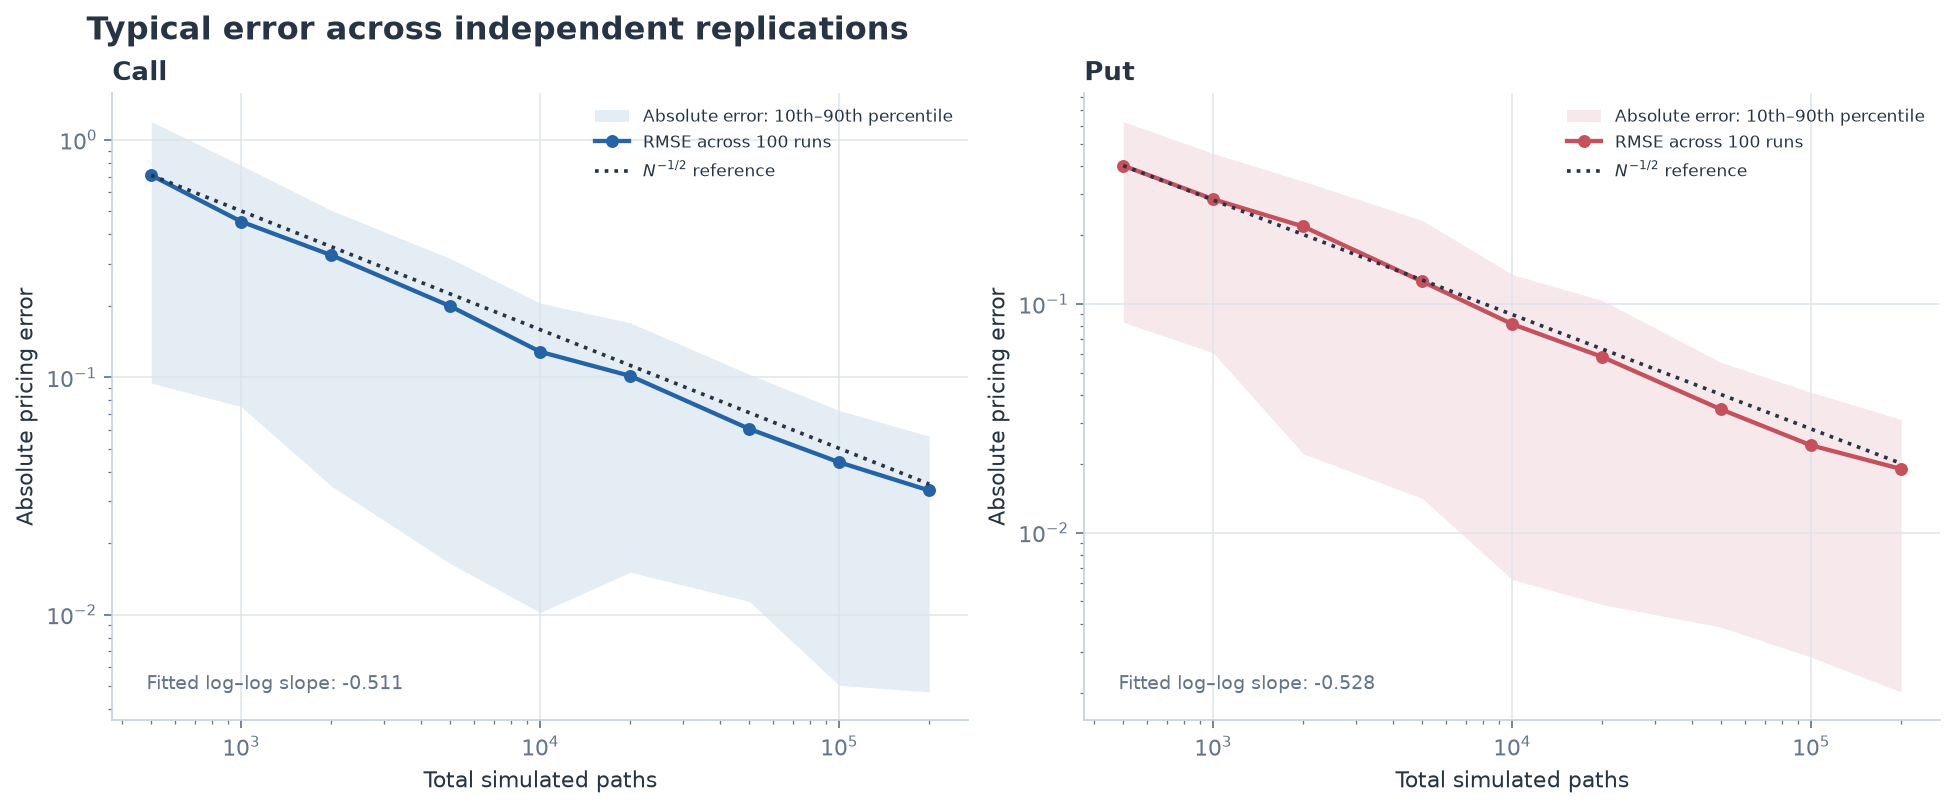

In [4]:
n_replications = 100
replication_errors = {kind: np.empty((n_replications, len(path_counts))) for kind in option_types}
for replication in range(n_replications):
    terminal = simulate_terminal_prices(
        parameters['S'], parameters['T'], parameters['r'], parameters['sigma'],
        max_paths, q=parameters['q'], rng=20261015 + replication,
    )
    for kind in option_types:
        payoff = (np.maximum(terminal - parameters['K'], 0.0) if kind == 'call'
                  else np.maximum(parameters['K'] - terminal, 0.0))
        discounted_payoff = discount * payoff
        cumulative_mean = np.cumsum(discounted_payoff)[path_counts - 1] / path_counts
        replication_errors[kind][replication] = cumulative_mean - analytical[kind]

rmse = {kind: np.sqrt(np.mean(errors ** 2, axis=0))
        for kind, errors in replication_errors.items()}
abs_error_quantiles = {
    kind: np.percentile(np.abs(errors), [10, 90], axis=0)
    for kind, errors in replication_errors.items()
}

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.1), constrained_layout=True)
for ax, kind in zip(axes, option_types):
    color = COLORS[kind]
    ax.fill_between(path_counts, abs_error_quantiles[kind][0], abs_error_quantiles[kind][1],
                    color=color, alpha=0.12, linewidth=0,
                    label='Absolute error: 10th–90th percentile')
    ax.plot(path_counts, rmse[kind], marker='o', markersize=5, color=color,
            label='RMSE across 100 runs')
    reference = rmse[kind][0] * np.sqrt(path_counts[0] / path_counts)
    ax.plot(path_counts, reference, color=INK, linestyle=':', linewidth=1.7,
            label=r'$N^{-1/2}$ reference')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total simulated paths')
    ax.set_ylabel('Absolute pricing error')
    ax.set_title(kind.title(), loc='left')
    ax.grid(which='minor', visible=False)
    ax.legend(loc='best', fontsize=8)
    slope = np.polyfit(np.log(path_counts), np.log(rmse[kind]), 1)[0]
    ax.text(0.04, 0.05, f'Fitted log–log slope: {slope:.3f}',
            transform=ax.transAxes, color=MUTED, fontsize=9)
fig.suptitle('Typical error across independent replications', x=0.04, ha='left')
plt.show()
for kind in option_types:
    slope = np.polyfit(np.log(path_counts), np.log(rmse[kind]), 1)[0]
    print(f"{kind.title()} empirical log–log RMSE slope: {slope:.3f} (theory: -0.5)")

## Takeaway

The one-run estimates can wiggle at every path count; that does not contradict convergence. What decreases with more paths is the distribution's typical spread. Across repeated runs, RMSE should approach a slope near $-1/2$ on a log–log chart, though finite samples and only 100 replications make the observed curve imperfect.

The intervals use a normal approximation for discounted payoffs. This notebook illustrates the convergence rate and variability; it does not provide a formal coverage study of the confidence intervals.

## Antithetic variates: estimator variance

Antithetic sampling uses each normal draw $Z$ together with $-Z$. For monotone vanilla call and put payoffs, these paired payoffs tend to be negatively correlated, reducing the variance of their average. The comparison below uses the same **total number of simulated paths** for both methods and estimates price variance across 100 independent replications. The plot shows the square root of that variance (RMSE for these unbiased estimators), in price units, so the reduction in typical pricing error is easier to interpret. Each antithetic confidence interval is based on the independent pair averages, not on treating the dependent paths as independent.

Variance reduction is measured as ordinary estimator variance divided by antithetic estimator variance; values above 1 indicate a reduction. Whiskers on the ratio plot are paired bootstrap 95% intervals from the 100 replications. The ratio is expected to be approximately stable as path count grows, but each estimate is noisy. Reduction is empirical for this setup, not guaranteed for every payoff or model.

In [5]:
from european_option_pricing.monte_carlo import monte_carlo_price

variance_path_counts = np.array([1_000, 2_000, 5_000, 10_000, 20_000, 50_000])
n_replications_variance = 100
n_bootstrap = 2_000
variance_results = {}
bootstrap_rng = np.random.default_rng(20261015)

for kind in option_types:
    ordinary = np.empty((n_replications_variance, len(variance_path_counts)))
    antithetic = np.empty_like(ordinary)
    for rep in range(n_replications_variance):
        for j, n_paths in enumerate(variance_path_counts):
            seed = 314159 + 10_000 * rep + int(n_paths)
            ordinary[rep, j] = monte_carlo_price(
                **parameters, option_type=kind, n_paths=int(n_paths), rng=seed
            ).price
            antithetic[rep, j] = monte_carlo_price(
                **parameters, option_type=kind, n_paths=int(n_paths), rng=seed,
                antithetic=True,
            ).price
    ordinary_variance = np.var(ordinary, axis=0, ddof=1)
    antithetic_variance = np.var(antithetic, axis=0, ddof=1)
    ratios = ordinary_variance / antithetic_variance
    ratio_intervals = np.empty((2, len(variance_path_counts)))
    for j in range(len(variance_path_counts)):
        indices = bootstrap_rng.integers(0, n_replications_variance,
                                         size=(n_bootstrap, n_replications_variance))
        ordinary_boot = np.var(ordinary[indices, j], axis=1, ddof=1)
        antithetic_boot = np.var(antithetic[indices, j], axis=1, ddof=1)
        ratio_intervals[:, j] = np.percentile(ordinary_boot / antithetic_boot, [2.5, 97.5])
    variance_results[kind] = {
        'ordinary_variance': ordinary_variance,
        'antithetic_variance': antithetic_variance,
        'variance_reduction_factor': ratios,
        'variance_reduction_ci': ratio_intervals,
    }

for kind in option_types:
    result = variance_results[kind]
    print(f"\n{kind.title()} variance ratio (95% bootstrap CI):")
    for j, n_paths in enumerate(variance_path_counts):
        lo, hi = result['variance_reduction_ci'][:, j]
        print(f"  {n_paths:>6,d} paths: {result['variance_reduction_factor'][j]:.2f}x [{lo:.2f}, {hi:.2f}]")


Call variance ratio (95% bootstrap CI):
   1,000 paths: 2.47x [1.57, 3.73]
   2,000 paths: 1.84x [1.24, 2.79]
   5,000 paths: 1.67x [1.10, 2.51]
  10,000 paths: 1.65x [1.18, 2.27]
  20,000 paths: 1.52x [1.11, 2.10]
  50,000 paths: 2.26x [1.53, 3.33]

Put variance ratio (95% bootstrap CI):
   1,000 paths: 1.74x [1.27, 2.37]
   2,000 paths: 1.46x [0.96, 2.22]
   5,000 paths: 1.73x [1.20, 2.44]
  10,000 paths: 1.59x [1.09, 2.19]
  20,000 paths: 1.63x [1.17, 2.29]
  50,000 paths: 1.70x [1.16, 2.50]


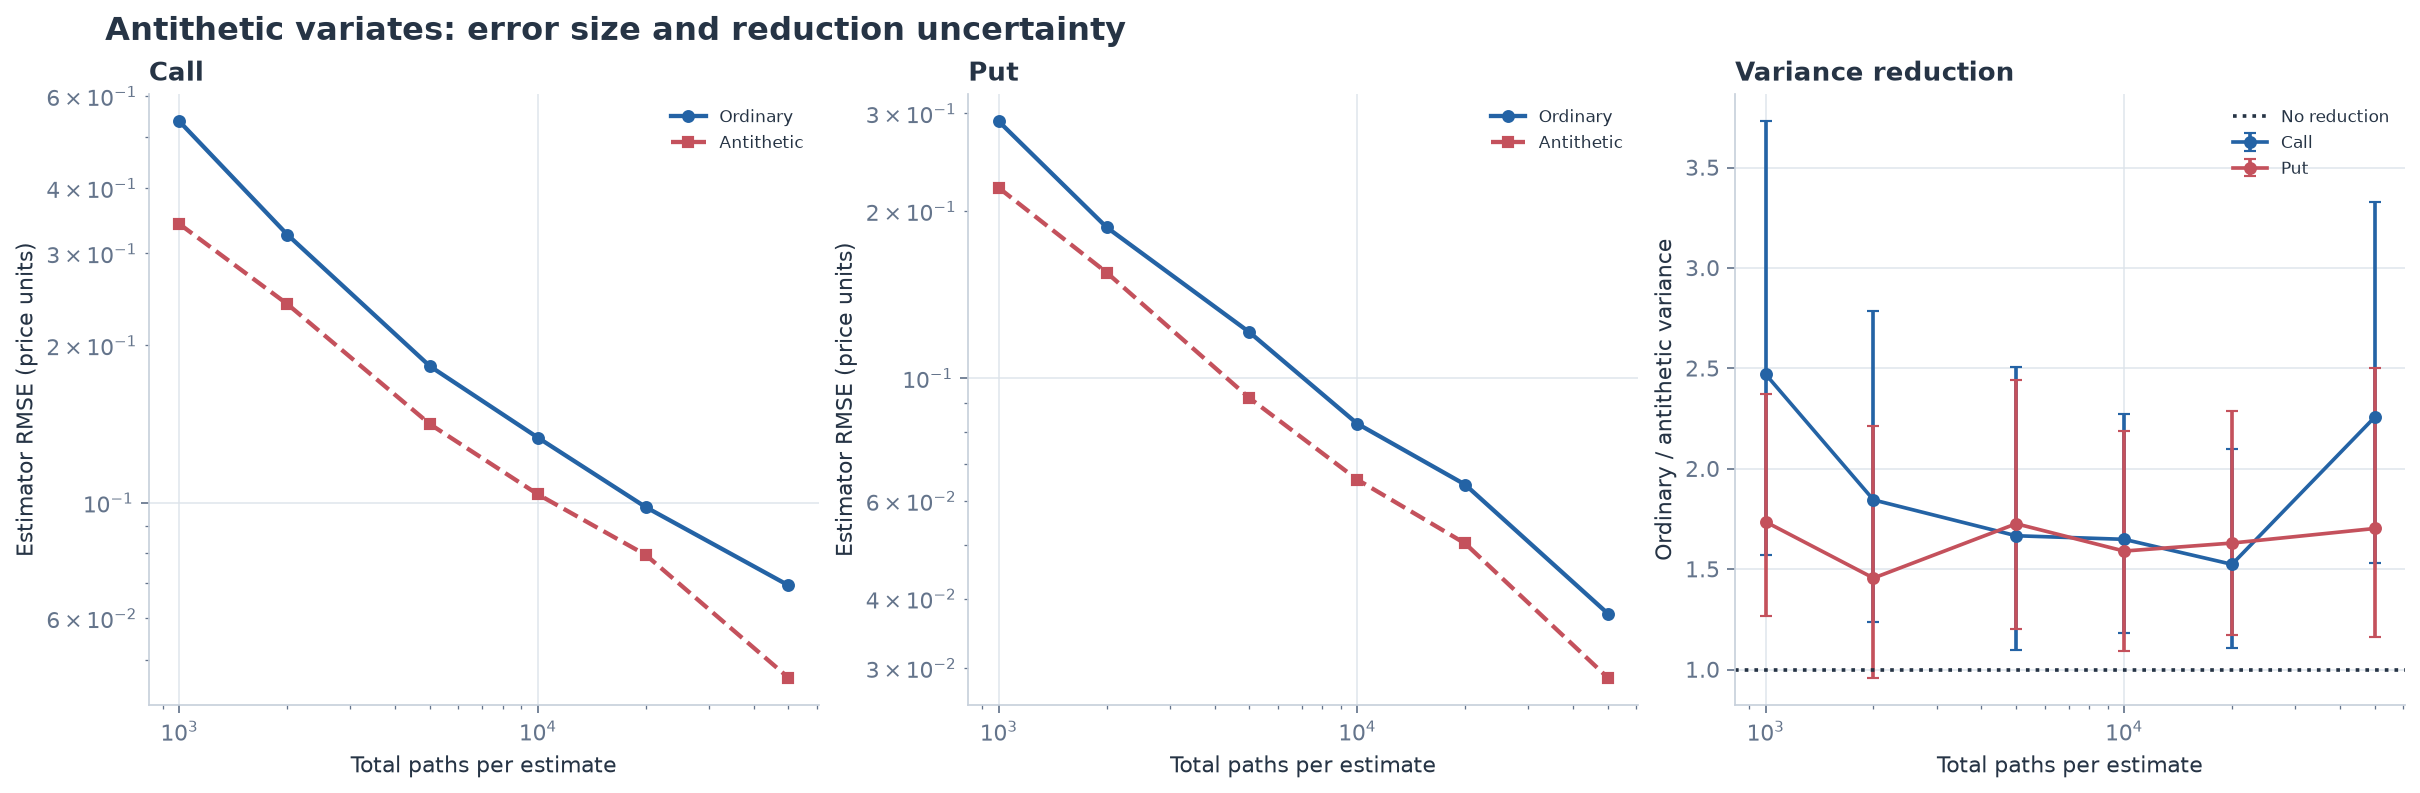

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), constrained_layout=True)
for ax, kind in zip(axes[:2], option_types):
    result = variance_results[kind]
    ordinary_rmse = np.sqrt(result['ordinary_variance'])
    antithetic_rmse = np.sqrt(result['antithetic_variance'])
    ax.plot(variance_path_counts, ordinary_rmse, marker='o', markersize=5,
            color=METHOD_COLORS['ordinary'], label='Ordinary')
    ax.plot(variance_path_counts, antithetic_rmse, marker='s', markersize=5,
            linestyle='--', color=METHOD_COLORS['antithetic'], label='Antithetic')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Total paths per estimate')
    ax.set_ylabel('Estimator RMSE (price units)')
    ax.set_title(kind.title(), loc='left')
    ax.grid(which='minor', visible=False)
    ax.legend(loc='best', fontsize=8)

ratio_ax = axes[2]
for kind in option_types:
    result = variance_results[kind]
    ratios = result['variance_reduction_factor']
    ci = result['variance_reduction_ci']
    ratio_ax.errorbar(
        variance_path_counts, ratios,
        yerr=np.vstack((ratios - ci[0], ci[1] - ratios)),
        marker='o', markersize=5, capsize=3, color=COLORS[kind],
        linewidth=1.7, label=kind.title(),
    )
ratio_ax.axhline(1.0, color=INK, linestyle=':', linewidth=1.7, label='No reduction')
ratio_ax.set_xscale('log')
ratio_ax.set_xlabel('Total paths per estimate')
ratio_ax.set_ylabel('Ordinary / antithetic variance')
ratio_ax.set_title('Variance reduction', loc='left')
ratio_ax.legend(loc='best', fontsize=8)
fig.suptitle('Antithetic variates: error size and reduction uncertainty', x=0.04, ha='left')
plt.show()